# 06 Analysis and ablations

The controlled study: decision rules, round one, the 2-seed final round, the 5-seed extension, where
the winner wins, and the ablations. Nothing is retrained. Every number is read from the run records in
`results/` and the decision rules are applied in code below.

In [1]:
import csv
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

sys.path.insert(0, os.path.abspath('../src'))
import local

CFG = local.config()
EV = CFG['evaluation']
COL = {'resgru': '#2a78d6', 'afnov4': '#eb6834', 'fmgwaclu': '#1baf7a', 'convlstm': '#eda100', 'patchafno': '#e87ba4'}
NAME = {'resgru': 'ResGRU-UNet', 'afnov4': 'AFNO V4', 'fmgwaclu': 'FMG-WACLU', 'convlstm': 'ConvLSTM', 'patchafno': 'patch AFNO'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False, 'axes.spines.right': False})
TEST = list(csv.DictReader(open(local.result('test_scores.csv'))))


def test(text):
    rows = [r for r in TEST if text in r['description']]
    assert len(rows) == 1, (text, len(rows))
    return float(rows[0]['private_score'])

## 1. The decision rule (fixed before training)

A network X is called better than AFNO V4 only if it leads by more than 0.003 on validation **and**
also scores higher on the held-out test set. A smaller validation gap is a tie; if validation and test
disagree, the result is inconclusive.

In [2]:
def verdict(val_x, val_ref, test_x, test_ref, thr=EV['decision_threshold']):
    d = val_x - val_ref
    if abs(d) <= thr:
        return 'tie'
    if (d > 0) != (test_x > test_ref):
        return 'inconclusive'
    return 'better' if d > 0 else 'worse'

## 2. Round one: five networks, one pipeline, seed 42

In [3]:
ref_val, ref_test = 0.9110, test('AFNO V4 seed 42 only')
print(f"{'network':12s} {'params':>10s} {'val':>8s} {'test':>8s}   verdict against AFNO V4")
print(f"{'AFNO V4':12s} {6980033:>10,} {ref_val:>8.4f} {ref_test:>8.4f}   (reference)")
for f, label in (('resgru', 'ResGRU-UNet in the V4'), ('fmgwaclu', 'FMG-WACLU in the V4'), ('patchafno', 'patch AFNO (B14 fixed)'), ('convlstm', 'ConvLSTM in the V4')):
    s = local.load_json(f, 'summary.json')
    v, t = s['best']['score'], test(label)
    print(f"{NAME[f]:12s} {s['params']:>10,} {v:>8.4f} {t:>8.4f}   {verdict(v, ref_val, t, ref_test)}")
print('pipeline check (AFNO V4 checkpoint re-evaluated inside the study code):', local.load_json('resgru', 'summary.json')['pipeline_check'])

network          params      val     test   verdict against AFNO V4
AFNO V4       6,980,033   0.9110   0.8762   (reference)
ResGRU-UNet   7,122,113   0.9158   0.8798   better
FMG-WACLU     3,454,645   0.9099   0.8710   tie
patch AFNO    5,708,800   0.9031   0.8530   worse
ConvLSTM     19,001,840   0.8945   0.8452   worse
pipeline check (AFNO V4 checkpoint re-evaluated inside the study code): {'logged': 0.91103, 'reproduced': 0.91103, 'diff': -0.0, 'v4_per_hour': {'gsmape': [0.05006, 0.08644, 0.11778, 0.14485, 0.1689, 0.18978, 0.20917, 0.22639, 0.24058, 0.25401, 0.26501, 0.27453, 0.28283, 0.28971, 0.29596, 0.30193], 'esmape': [0.04721, 0.08349, 0.11517, 0.14397, 0.17054, 0.19723, 0.22368, 0.24946, 0.2766, 0.2959, 0.31802, 0.33669, 0.35485, 0.37064, 0.38589, 0.3973], 'ecorr': [0.99132, 0.97673, 0.96567, 0.95417, 0.94519, 0.9366, 0.92847, 0.92209, 0.9131, 0.90844, 0.90335, 0.90276, 0.89908, 0.89661, 0.89226, 0.88736]}, 'v4_terms': {'gsmape': 0.21237, 'esmape': 0.24792, 'ecorr': 0.92645}}


Validation and test order the five networks the same way. ResGRU-UNet is the only network better
than AFNO V4 under the rule.

## 3. Final round: two seeds, the full V4 recipe

In [4]:
fr = local.load_json('final', 'summary.json')['final_round']
for f in ('afnov4', 'resgru'):
    print(f"{NAME[f]:12s} 2-seed val {fr[f]['two_seed']['score']:.5f}, + calibration {fr[f]['two_seed_cal_in_sample']['score']:.5f}")
print('validation gap, 2-seed means:', fr['val_gap_two_seed'])
print('test: ResGRU-UNet 2 seeds + calibration', test('ResGRU-UNet 2 seeds + V4 per-horizon'), '| AFNO V4 (its own 2-seed submission) 0.8833')

AFNO V4      2-seed val 0.91311, + calibration 0.91430
ResGRU-UNet  2-seed val 0.91747, + calibration 0.91982
validation gap, 2-seed means: 0.00436
test: ResGRU-UNet 2 seeds + calibration 0.8898 | AFNO V4 (its own 2-seed submission) 0.8833


## 4. Five seeds per finalist

In [5]:
A = local.load_json('analysis', 'analysis.json')
assert A['all_checks_pass']
sv = {f: [A['seeds_val'][f][str(s)]['score'] for s in EV['seeds']] for f in ('afnov4', 'resgru')}
st = {'afnov4': [test('AFNO V4 seed 42 only'), test('AFNO V4 seed 1337 only')] + [test(f'AFNO V4 seed {s} only') for s in (1, 2, 3)],
      'resgru': [test('ResGRU-UNet in the V4 pipeline')] + [test(f'ResGRU-UNet seed {s} only') for s in (1337, 1, 2, 3)]}
for f in ('afnov4', 'resgru'):
    print(f"{NAME[f]:12s} val seeds {np.round(sv[f], 5)}  mean {np.mean(sv[f]):.5f} sd {np.std(sv[f], ddof=1):.5f}")
    print(f"{'':12s} test seeds {np.round(st[f], 4)}  mean {np.mean(st[f]):.5f} sd {np.std(st[f], ddof=1):.5f}")
wins_val = sum(r > a for r in sv['resgru'] for a in sv['afnov4'])
wins_test = sum(r > a for r in st['resgru'] for a in st['afnov4'])
print(f'ResGRU-UNet wins {wins_val} of 25 seed pairs on validation and {wins_test} of 25 on test')
g = A['gap']
print(f"5-seed ensemble gap on validation {g['ensemble']:+.5f}, 95% block bootstrap {g['ensemble_ci95']} "
      f"(blocks of {g['block']} windows within each month, {g['n_boot']} resamples)")

AFNO V4      val seeds [0.91103 0.91141 0.91178 0.91227 0.9108 ]  mean 0.91146 sd 0.00059
             test seeds [0.8762 0.8749 0.8758 0.8767 0.8734]  mean 0.87540 sd 0.00130
ResGRU-UNet  val seeds [0.91579 0.91523 0.91687 0.91784 0.91579]  mean 0.91630 sd 0.00104
             test seeds [0.8798 0.8788 0.8796 0.8805 0.881 ]  mean 0.87994 sd 0.00085
ResGRU-UNet wins 25 of 25 seed pairs on validation and 25 of 25 on test
5-seed ensemble gap on validation +0.00479, 95% block bootstrap [0.00383, 0.00578] (blocks of 13 windows within each month, 2000 resamples)


5-seed rule: val gap > 0.003 with interval above 0, calibrated test higher, mean single-seed test higher: (True, True, True)
verdict: ResGRU-UNet better


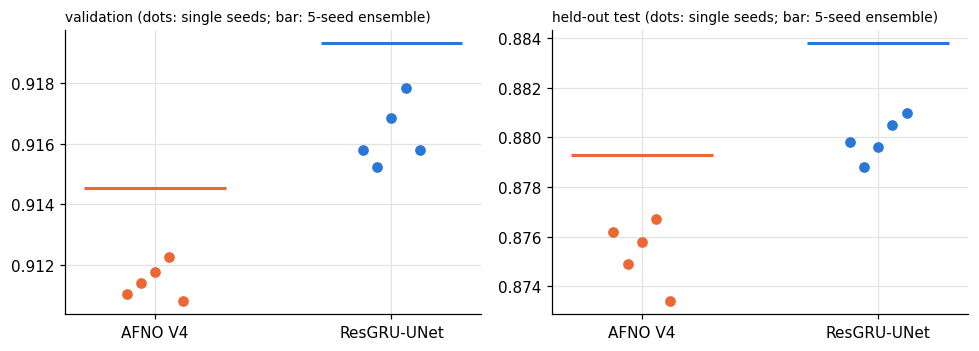

In [6]:
ens = {f: A['ensemble_val'][f]['score'] for f in ('afnov4', 'resgru')}
cal_test = {f: test(f'{NAME[f]} 5-seed mean + V4') for f in ('afnov4', 'resgru')}
rule = (g['ensemble'] > EV['decision_threshold'] and g['ensemble_ci95'][0] > 0,
        cal_test['resgru'] > cal_test['afnov4'], bool(np.mean(st['resgru']) > np.mean(st['afnov4'])))
print('5-seed rule: val gap > 0.003 with interval above 0, calibrated test higher, mean single-seed test higher:', rule)
print('verdict:', 'ResGRU-UNet better' if all(rule) else 'not established')

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for j, (title, vals, e) in enumerate((('validation', sv, ens), ('held-out test', st, {f: test(f'{NAME[f]} 5-seed mean, no calibration') for f in sv}))):
    for i, f in enumerate(('afnov4', 'resgru')):
        ax[j].scatter(i + np.linspace(-0.12, 0.12, 5), vals[f], color=COL[f], zorder=3)
        ax[j].hlines(e[f], i - 0.3, i + 0.3, color=COL[f], lw=2)
    ax[j].set_xticks([0, 1]); ax[j].set_xticklabels([NAME['afnov4'], NAME['resgru']]); ax[j].set_title(title + ' (dots: single seeds; bar: 5-seed ensemble)', loc='left', fontsize=9)
plt.tight_layout(); plt.show()

## 5. Where ResGRU-UNet wins

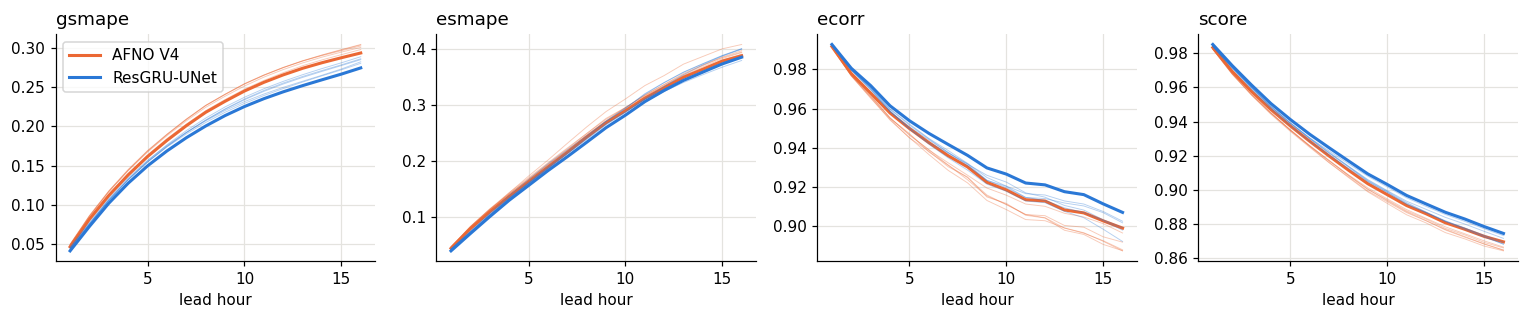

score gap by lead hour: [0.0018 0.0034 0.0037 0.0035 0.0037 0.0041 0.0048 0.0054 0.0057 0.006
 0.0059 0.0057 0.0061 0.006  0.0057 0.0049]
score gap by month: {'APRIL_16': 0.0064, 'JULY_16': 0.0035, 'OCT_16': 0.0038, 'DEC_16': 0.0055}


In [7]:
hrs = np.arange(1, 17)
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for k, key in enumerate(('gsmape', 'esmape', 'ecorr', 'score')):
    for f in ('afnov4', 'resgru'):
        for s in EV['seeds']:
            ax[k].plot(hrs, A['per_hour'][f]['seeds'][str(s)][key], color=COL[f], lw=0.6, alpha=0.35)
        ax[k].plot(hrs, A['per_hour'][f]['ensemble'][key], color=COL[f], lw=2, label=NAME[f])
    ax[k].set_title(key, loc='left'); ax[k].set_xlabel('lead hour')
ax[0].legend(); plt.tight_layout(); plt.show()
gap_h = np.array(A['per_hour']['resgru']['ensemble']['score']) - np.array(A['per_hour']['afnov4']['ensemble']['score'])
print('score gap by lead hour:', np.round(gap_h, 4))
print('score gap by month:', {m: round(A['per_month']['resgru'][m] - A['per_month']['afnov4'][m], 4) for m in A['months']})

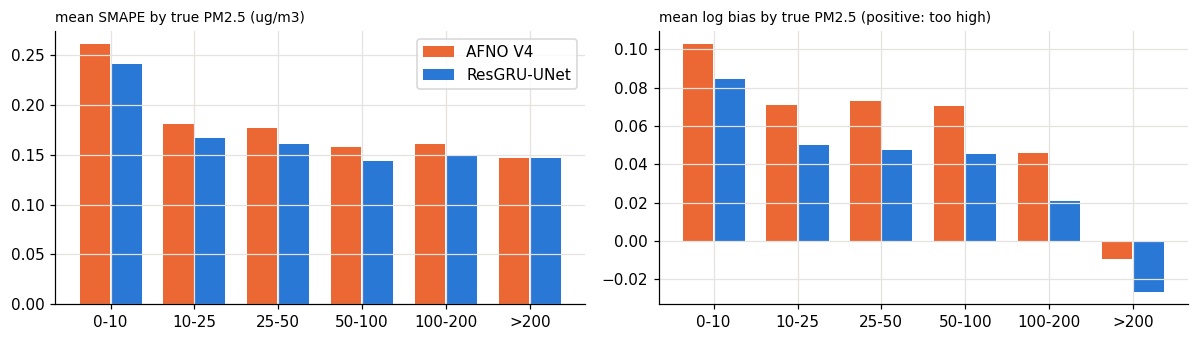

episode vs other cells: {'afnov4': {'episode': {'smape': 0.21603, 'log_bias': -0.15958}, 'other': {'smape': 0.2044, 'log_bias': 0.08373}}, 'resgru': {'episode': {'smape': 0.20802, 'log_bias': -0.15697}, 'other': {'smape': 0.18824, 'log_bias': 0.06189}}}


In [8]:
bins = A['bins']
lab = [f"{b['lo']}-{b['hi']}" if b['hi'] else f">{b['lo']}" for b in bins['resgru']]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, f in enumerate(('afnov4', 'resgru')):
    for k, key in enumerate(('smape', 'log_bias')):
        ax[k].bar(np.arange(6) + (i - 0.5) * 0.38, [b[key] for b in bins[f]], 0.36, color=COL[f], label=NAME[f])
for k, t in enumerate(('mean SMAPE by true PM2.5 (ug/m3)', 'mean log bias by true PM2.5 (positive: too high)')):
    ax[k].set_xticks(np.arange(6)); ax[k].set_xticklabels(lab); ax[k].set_title(t, loc='left', fontsize=9)
ax[0].legend(); plt.tight_layout(); plt.show()
print('episode vs other cells:', A['episode_split'])

## 6. Maps

Per-cell errors averaged over the 214 validation windows and 16 lead hours (5-seed means).

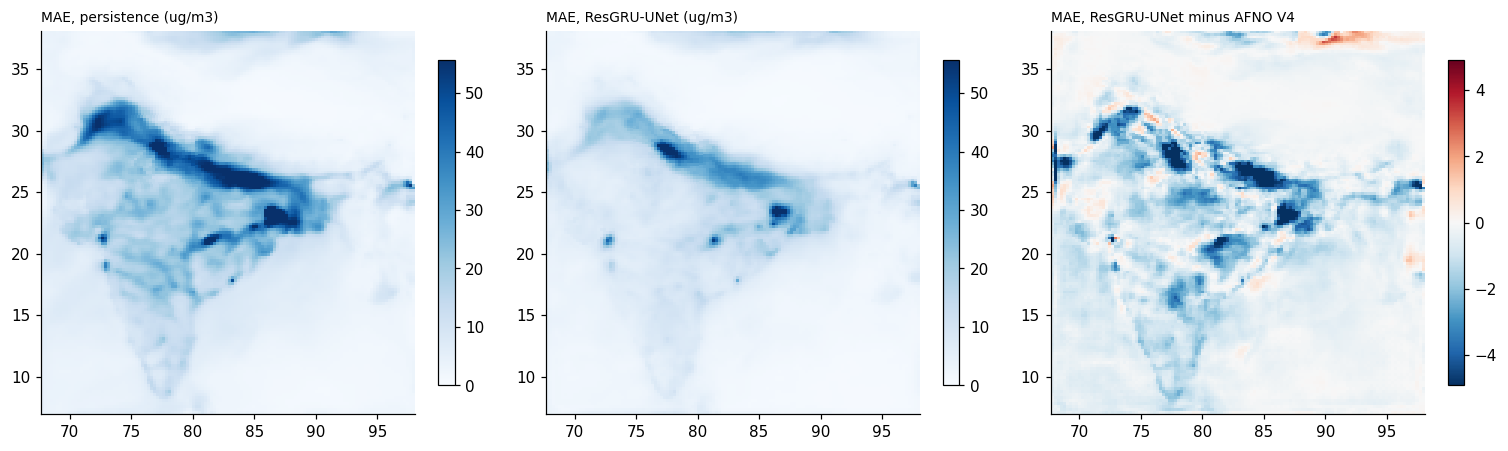

ResGRU-UNet has the lower MAE in 90.5% of cells and the lower SMAPE in 94.7%
median per-cell R2 over time: {'persistence': 0.694, 'afnov4': 0.846, 'resgru': 0.872}


In [9]:
import numpy as _np
M = dict(_np.load(local.result('maps', 'maps.npz')))
lon, lat = M['lon'], M['lat']
d = M['resgru_mae'] - M['afnov4_mae']
lim = float(np.percentile(np.abs(d), 99))
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a_, z, kw, t in ((ax[0], M['persistence_mae'], dict(cmap='Blues', vmin=0, vmax=np.percentile(M['persistence_mae'], 99)), 'MAE, persistence (ug/m3)'),
                     (ax[1], M['resgru_mae'], dict(cmap='Blues', vmin=0, vmax=np.percentile(M['persistence_mae'], 99)), 'MAE, ResGRU-UNet (ug/m3)'),
                     (ax[2], d, dict(cmap='RdBu_r', norm=TwoSlopeNorm(0, -lim, lim)), 'MAE, ResGRU-UNet minus AFNO V4')):
    im = a_.pcolormesh(lon, lat, z, shading='auto', **kw)
    fig.colorbar(im, ax=a_, shrink=0.8); a_.set_title(t, loc='left', fontsize=9); a_.set_aspect('equal'); a_.grid(False)
plt.tight_layout(); plt.show()
print(f'ResGRU-UNet has the lower MAE in {100 * (d < 0).mean():.1f}% of cells and the lower SMAPE in {100 * A["cells_resgru_lower_smape"]:.1f}%')
print('median per-cell R2 over time:', {k: round(float(np.median(M[k + '_r2'])), 3) for k in ('persistence', 'afnov4', 'resgru')})

## 7. Pipeline against backbone

The same network in its own earlier pipeline and in the V4 pipeline (test, seed 42, no calibration).
Each gain bundles every pipeline change.

In [10]:
early = {r['iteration']: r for r in csv.DictReader(open(local.result('earlier_iterations.csv')))}
for net, own, key in (('ResGRU-UNet', float(early['2']['test_score']), 'ResGRU-UNet in the V4'),
                      ('FMG-WACLU', float(early['original']['test_score']), 'FMG-WACLU in the V4'),
                      ('patch AFNO', float(early['1']['test_score']), 'patch AFNO (B14 fixed)')):
    print(f'{net:12s} own pipeline {own:.4f} -> V4 pipeline {test(key):.4f}  gain {test(key) - own:+.4f}')
print(f"backbone gap at the same setting (seed 42): {test('ResGRU-UNet in the V4') - ref_test:+.4f}")

ResGRU-UNet  own pipeline 0.8506 -> V4 pipeline 0.8798  gain +0.0292
FMG-WACLU    own pipeline 0.8465 -> V4 pipeline 0.8710  gain +0.0245
patch AFNO   own pipeline 0.8218 -> V4 pipeline 0.8530  gain +0.0312
backbone gap at the same setting (seed 42): +0.0036


## 8. Ablations: why ResGRU-UNet wins

Four hypotheses, one change each, one seed each, with predictions written down before the runs. A
change counts only if it moves validation by more than $\max(2\,\mathrm{sd}, 0.002)$ from its family's
5-seed mean, in the predicted direction.

In [11]:
spec = {'afnov4_allskip': ('H1', 'afnov4', +1, 'ablations_a'), 'afnov4_pad': ('H2', 'afnov4', +1, 'ablations_b'),
        'afnov4_nosparse': ('H3', 'afnov4', +1, 'ablations_a'), 'resgru_norec': ('H4', 'resgru', -1, 'ablations_b')}
mean = {f: np.mean(sv[f]) for f in sv}
sd = {f: np.std(sv[f], ddof=1) for f in sv}
G = mean['resgru'] - mean['afnov4']
labels = {'afnov4_allskip': 'H1: AFNO V4 with all-hour skips', 'afnov4_pad': 'H2: AFNO V4 with zero-padded',
          'afnov4_nosparse': 'H3: AFNO V4 with soft-threshold 0', 'resgru_norec': 'H4: ResGRU-UNet without ConvGRU'}
print(f'gap G = {G:.5f} (difference of the unrounded 5-seed means; 0.00484 from the rounded means)')
for v, (h, f, sign, folder) in spec.items():
    val = local.load_json(folder, f'summary_{v}.json')['best']['score']
    d = val - mean[f]
    t = max(2 * sd[f], EV['ablation_threshold'])
    res = 'not resolved' if abs(d) <= t else ('supported' if np.sign(d) == sign else 'contradicted')
    print(f'{h} {v:16s} val {val:.5f}  d {d:+.5f}  t {t:.5f}  d/G {d / G:+.2f}  test {test(labels[v]):.4f}  -> {res}')

gap G = 0.00485 (difference of the unrounded 5-seed means; 0.00484 from the rounded means)
H1 afnov4_allskip   val 0.91259  d +0.00113  t 0.00200  d/G +0.23  test 0.8748  -> not resolved
H2 afnov4_pad       val 0.91062  d -0.00084  t 0.00200  d/G -0.17  test 0.8745  -> not resolved
H3 afnov4_nosparse  val 0.91094  d -0.00052  t 0.00200  d/G -0.11  test 0.8758  -> not resolved
H4 resgru_norec     val 0.91456  d -0.00174  t 0.00209  d/G -0.36  test 0.8798  -> not resolved
